 # Exploring the North Atlantic Oscillation



 The North Atlantic Oscillation (NAO) is one of the most important climate patterns in the North Atlantic region.

 In the North Atlantic we can observe two main patterns of sea level pressure:

 A high pressure system close to the Azores and a low pressure system near Iceland.

 The NAO-index measures how strong the difference between these two pressure systems is.



 There is no single definition of the NAO-index but two main approaches exist:

 1. **Station-based approach:** Uses the difference in sea level pressure between specific locations (e.g., Azores and Iceland).

 2. **Empirical Orthogonal Function (EOF) approach:** Uses statistical methods to identify the dominant pattern of variability in the North Atlantic region.

 We will explore both approaches here.

 # Modules

In [4]:
import xarray as xr
import earthkit.plots as ekp
import earthkit.data as ekd
import earthkit.transforms as ekt

 # Loading Mean Sea Level Pressure for the North Atlantic Region



 We base our analysis on the ERA5 mean sea level pressure (MSLP) data.

 I downloaded the data with 6H timesteps between 2015 and 2025.

 This dataset is quite large: ~31 GB in total.

 Hence we load it into chunks, which gives us the possibility for parallell computing.

 No worries, xarray and dask will do that for us automatically.

In [5]:
# Load MSLP data and select North Atlantic region
north_atlantic_box = [-80, 0, 0, 80]  # earthkit expects: [lon_min, lon_max, lat_min, lat_max]
mslp = xr.open_mfdataset("C:/local_desktop/projects/website-coding/data/raw/ERA5/mslp/*.nc")
north_atlantic_mslp = mslp["msl"].sel(
    longitude=slice(north_atlantic_box[0], north_atlantic_box[1]),
    latitude=slice(north_atlantic_box[3], north_atlantic_box[2])
)
north_atlantic_mslp

<xarray.DataArray 'msl' (valid_time: 16072, latitude: 321, longitude: 321)> Size: 7GB
dask.array<getitem, shape=(16072, 321, 321), dtype=float32, chunksize=(244, 61, 240), chunktype=numpy.ndarray>
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 129kB 2015-01-01 ... 2025-12-31T1...
    expver      (valid_time) <U4 257kB dask.array<chunksize=(1460,), meta=np.ndarray>
  * latitude    (latitude) float64 3kB 80.0 79.75 79.5 79.25 ... 0.5 0.25 0.0
  * longitude   (longitude) float64 3kB -80.0 -79.75 -79.5 ... -0.5 -0.25 0.0
    number      int64 8B 0
Attributes: (12/32)
    GRIB_paramId:                             151
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      519840
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               Pa
    long_name:                                Mean sea level pressure
    units:                                    Pa
    standard_name:                            air_pressure_at_mean_sea_level
    GRIB_surface:                             0.0

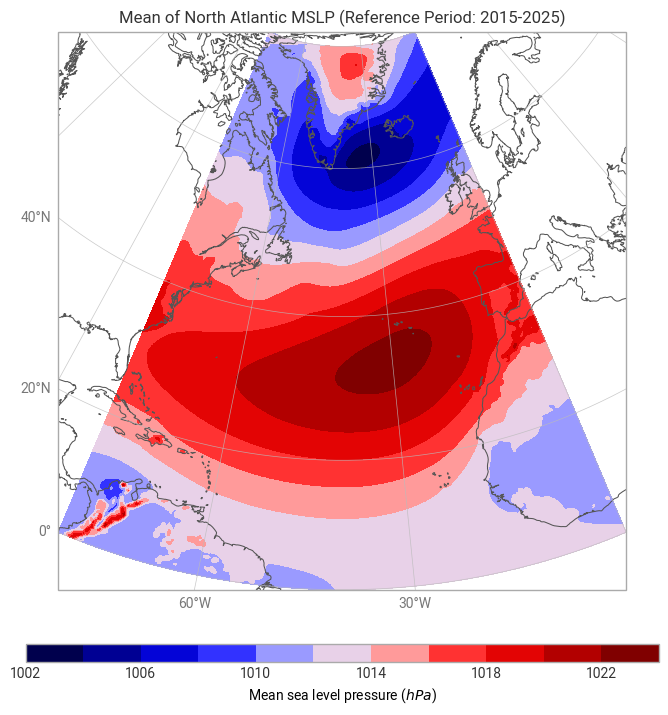

In [6]:
# Compute mean over the reference period
climatology = north_atlantic_mslp.mean(dim="valid_time").compute()
chart = ekp.Map(domain=north_atlantic_box)
chart.contourf(climatology, units="hPa", cmap="seismic")
chart.coastlines()
chart.gridlines()
chart.title("Mean of North Atlantic MSLP (Reference Period: 2015-2025)")
chart.legend(label="{variable_name} ({units})")
chart.show()

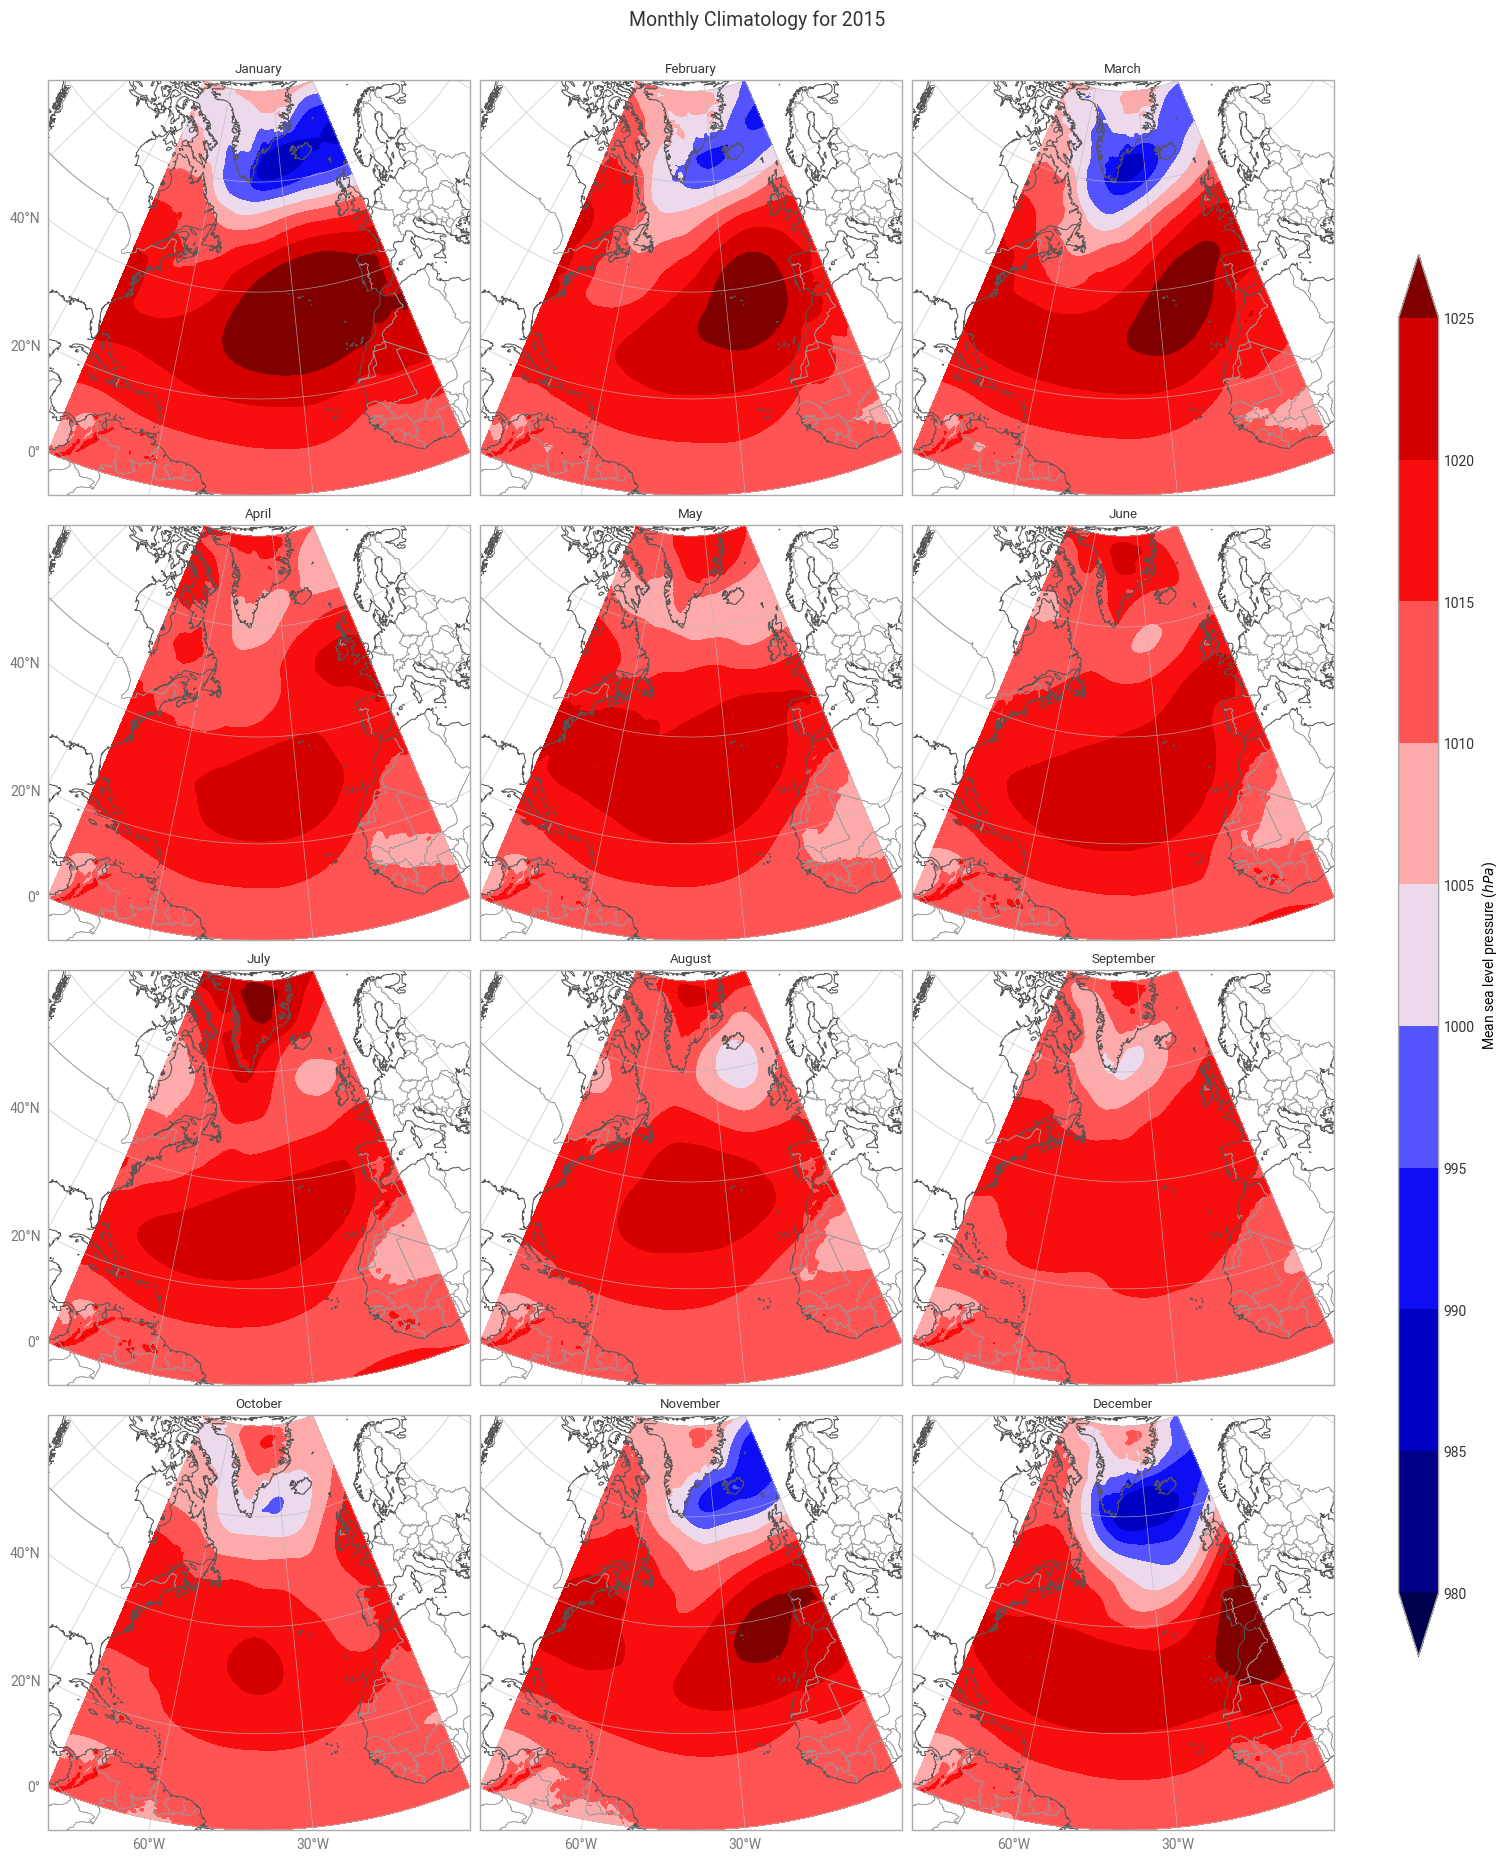

In [ ]:
# Compute monthly climatology for 2015
monthly_climatology_2015 = (north_atlantic_mslp
                            .sel(valid_time="2015")
                            .groupby("valid_time.month")
                            .mean(dim="valid_time")
                            )

figure = ekp.Figure(rows=4, columns=3, size=(15, 18))
months = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

style = ekp.styles.Style(
    levels=list(range(980, 1030, 5)),
    colors="seismic",
    units="hPa",
    extend="both",
)
for i in range(12):
    subplot = figure.add_map(domain=north_atlantic_box) 
    month_data = monthly_climatology_2015.sel(month=i+1) # Nutze hier das jeweilige Monatsfeld
    subplot.contourf(month_data, style=style)
    subplot.title(f"{months[i]}")
    
figure.coastlines()
figure.borders()
figure.gridlines()
figure.legend(location="right")
figure.title("Monthly Climatology of MSLP for 2015")
figure.show()